<a href="https://colab.research.google.com/github/yasminasouki/DataAnalysis/blob/dev/01_download_explore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [9]:
!kaggle competitions download -c rsna-pneumonia-detection-challenge -p /content/rsna
!unzip -q /content/rsna/rsna-pneumonia-detection-challenge.zip -d /content/rsna
!ls /content/rsna

100% 3.66G/3.66G [00:43<00:00, 90.9MB/s]

'GCP Credits Request Link - RSNA.txt'	  stage_2_test_images
 rsna-pneumonia-detection-challenge.zip   stage_2_train_images
 stage_2_detailed_class_info.csv	  stage_2_train_labels.csv
 stage_2_sample_submission.csv


In [10]:
import pandas as pd

labels = pd.read_csv('/content/rsna/stage_2_train_labels.csv')
classes = pd.read_csv('/content/rsna/stage_2_detailed_class_info.csv')

print("Rows in labels file:", labels.shape)
print("Unique patients:", labels["patientId"].nunique())
print(classes.drop_duplicates("patientId")["class"].value_counts())

Rows in labels file: (30227, 6)
Unique patients: 26684
class
No Lung Opacity / Not Normal    11821
Normal                           8851
Lung Opacity                     6012
Name: count, dtype: int64


In [11]:
!mkdir -p "/content/drive/MyDrive/pneumonia-project"
!cp /content/rsna/stage_2_train_labels.csv /content/rsna/stage_2_detailed_class_info.csv "/content/drive/MyDrive/pneumonia-project/"
print("Saved to Drive")

Saved to Drive


In [12]:
!pip install -q pydicom
import pydicom, os
from tqdm import tqdm

img_dir = '/content/rsna/stage_2_train_images'
rows = []
for f in tqdm(os.listdir(img_dir)):
    ds = pydicom.dcmread(os.path.join(img_dir, f), stop_before_pixels=True)
    rows.append({
        "patientId": f.replace(".dcm", ""),
        "age": int(ds.PatientAge),
        "sex": ds.PatientSex,
        "view": ds.ViewPosition,
        "height_px": ds.Rows,
        "width_px": ds.Columns,
    })

meta = pd.DataFrame(rows)
one_per_patient = classes.drop_duplicates("patientId")
meta = meta.merge(one_per_patient, on="patientId")

meta.to_csv('/content/drive/MyDrive/pneumonia-project/metadata.csv', index=False)
print(meta.shape)
meta.head()

100%|██████████| 26684/26684 [00:47<00:00, 565.11it/s]


(26684, 7)


,patientId,age,sex,view,height_px,width_px,class
0,b84112a1-ffcd-4897-baa1-652f4e460287,32,F,AP,1024,1024,Lung Opacity
1,5b2e6149-2308-4f75-bf96-a0f062de13cc,22,M,PA,1024,1024,Normal
2,a9b33024-ace7-424e-97c8-3082b8f5681f,41,M,PA,1024,1024,No Lung Opacity / Not Normal
3,2139214a-4a50-4144-9c2d-eb4c929e1e7e,29,M,AP,1024,1024,Lung Opacity
4,c236d6e2-1fca-40c5-a0fe-a91ff60883c9,24,F,AP,1024,1024,Lung Opacity


In [13]:
print(meta["age"].describe())
print("\nSex:\n", meta["sex"].value_counts())
print("\nView:\n", meta["view"].value_counts())
print("\nImage sizes:\n", meta[["height_px", "width_px"]].value_counts())
print("\nView by class (%):")
print(pd.crosstab(meta["class"], meta["view"], normalize="index").round(3) * 100)

count    26684.000000
mean        47.030018
std         16.810578
min          1.000000
25%         34.000000
50%         49.000000
75%         59.000000
max        155.000000
Name: age, dtype: float64

Sex:
 sex
M    15166
F    11518
Name: count, dtype: int64

View:
 view
PA    14511
AP    12173
Name: count, dtype: int64

Image sizes:
 height_px  width_px
1024       1024        26684
Name: count, dtype: int64

View by class (%):
view                            AP    PA
class                                   
Lung Opacity                  77.6  22.4
No Lung Opacity / Not Normal  49.7  50.3
Normal                        18.5  81.5


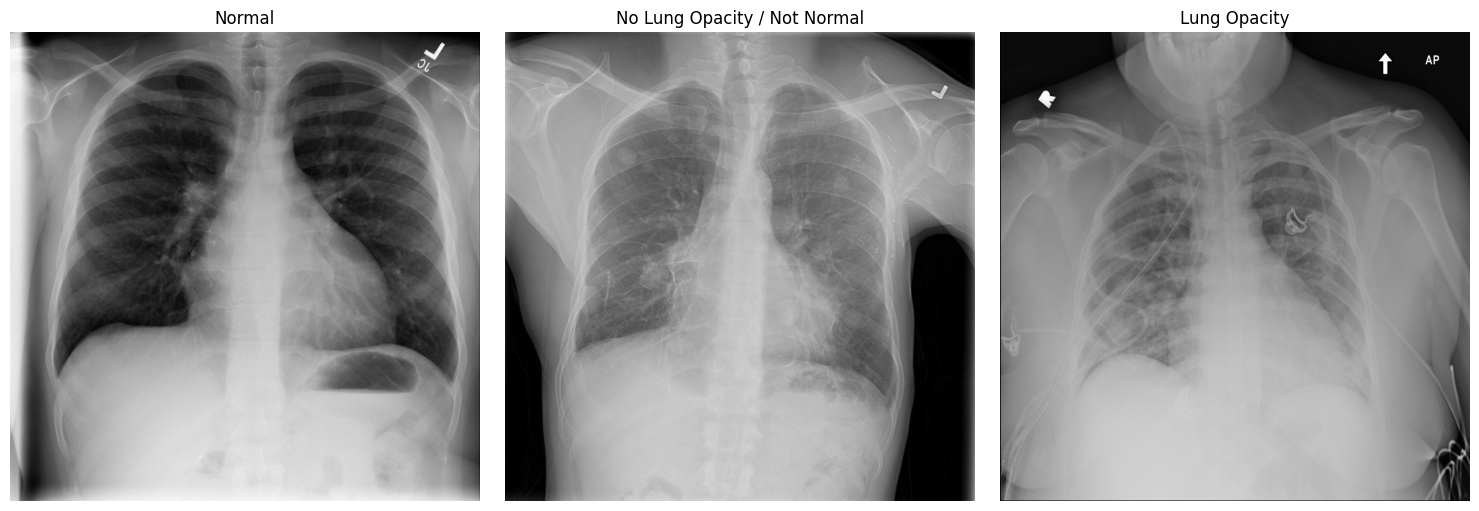

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, cls in zip(axes, ["Normal", "No Lung Opacity / Not Normal", "Lung Opacity"]):
    pid = meta[meta["class"] == cls].iloc[0]["patientId"]
    img = pydicom.dcmread(f"{img_dir}/{pid}.dcm").pixel_array
    ax.imshow(img, cmap="gray")
    ax.set_title(cls)
    ax.axis("off")
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/pneumonia-project/example_xrays.png', dpi=150, bbox_inches="tight")
plt.show()

In [15]:
print("Ages over 100:", (meta["age"] > 100).sum())
print(meta[meta["age"] > 100][["patientId", "age", "class"]])

Ages over 100: 5
                                  patientId  age                         class
7675   a4e8e96d-93a6-4251-b617-91382e610fab  153  No Lung Opacity / Not Normal
10065  f632328d-5819-4b29-b54f-adf4934bbee6  155                        Normal
17132  ec3697bd-184e-44ba-9688-ff8d5fbf9bbc  150                        Normal
18793  3b8b8777-a1f6-4384-872a-28b95f59bf0d  148                        Normal
19634  73aeea88-fc48-4030-8564-0a9d7fdecac4  151  No Lung Opacity / Not Normal


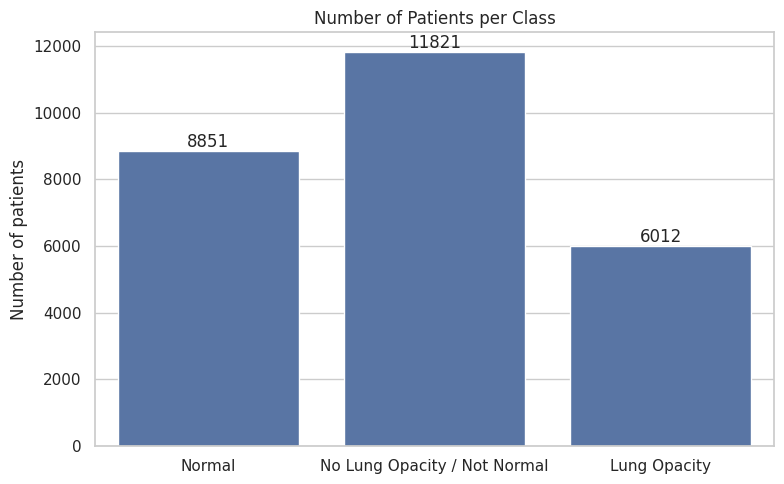

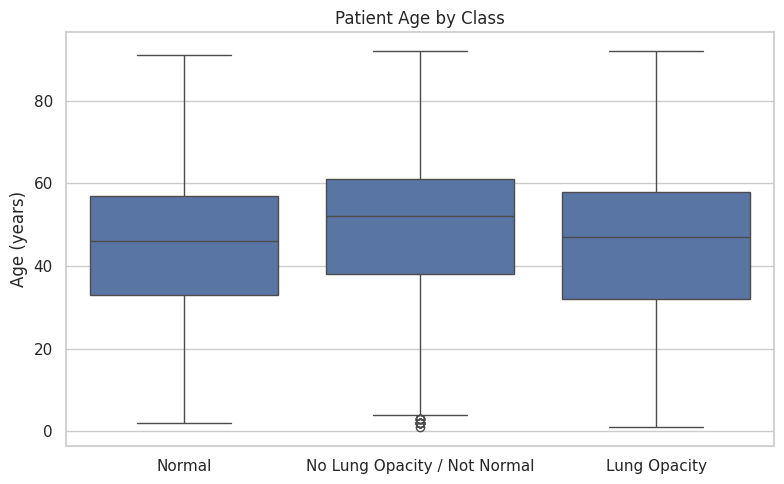

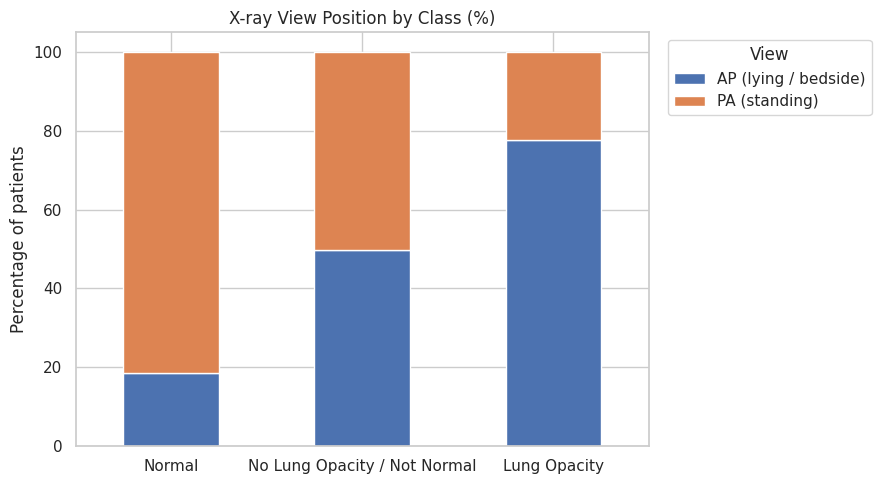

In [17]:
import seaborn as sns
sns.set_theme(style="whitegrid")
order = ["Normal", "No Lung Opacity / Not Normal", "Lung Opacity"]
fig_dir = '/content/drive/MyDrive/pneumonia-project/figures'
os.makedirs(fig_dir, exist_ok=True)

# 1. Class distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=meta, x="class", order=order)
ax.bar_label(ax.containers[0])
plt.title("Number of Patients per Class")
plt.xlabel(""); plt.ylabel("Number of patients")
plt.tight_layout()
plt.savefig(f"{fig_dir}/01_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Age by class (valid ages only)
plt.figure(figsize=(8, 5))
sns.boxplot(data=meta[meta["age"] <= 100], x="class", y="age", order=order)
plt.title("Patient Age by Class")
plt.xlabel(""); plt.ylabel("Age (years)")
plt.tight_layout()
plt.savefig(f"{fig_dir}/02_age_by_class.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. View position by class
pct = pd.crosstab(meta["class"], meta["view"], normalize="index").loc[order] * 100
ax = pct.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("X-ray View Position by Class (%)")
plt.xlabel(""); plt.ylabel("Percentage of patients"); plt.xticks(rotation=0)
plt.legend(title="View", labels=["AP (lying / bedside)", "PA (standing)"],
           bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{fig_dir}/03_view_by_class.png", dpi=300, bbox_inches="tight")
plt.show()